# Single-stock risk report

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scrapbook as sb
from IPython.display import display
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

## Parameters

In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [3]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/genrikh/School/UCB/Courses/Pre Program Courses/Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Genrikh_Kuznetsov/data/data.db"


In [4]:
VOL_WINDOW = 20
MA_WINDOW = 50
TRADING_DAYS = 252
RISK_FREE_RATE = 0.02

COLORS = {'high': '#d62728', 'low': '#2ca02c', 'warmup': '#9e9e9e', 'ma': '#1f3b73',
          'vol': '#6a3d9a', 'drawdown': '#c0392b', 'mean': '#333333'}

## Loading the data

In [5]:
def load_prices(db_path, ticker, start_date, end_date):
    """Load cleaned daily prices for one ticker and date range (inclusive), indexed by date."""
    database = Path(db_path).expanduser().resolve()
    if not database.is_file():
        raise FileNotFoundError(f'Database not found: {database}. Run 01_data_cleaning.ipynb first.')
    if pd.Timestamp(start_date) > pd.Timestamp(end_date):
        raise ValueError(f'start_date {start_date} is after end_date {end_date}.')
    query = """
        SELECT ts, open, high, low, close, adj_close, volume,
               price_repaired, volume_repaired, adj_close_repaired, extreme_return_flag
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts BETWEEN ? AND ?
        ORDER BY ts
    """
    with closing(sqlite3.connect(database.as_uri() + '?mode=ro', uri=True)) as conn:
        return pd.read_sql_query(query, conn, params=(ticker, start_date, end_date),
                                 parse_dates=['ts'], index_col='ts')


df = load_prices(db_path, ticker, start_date, end_date)
if df.empty:
    raise ValueError(f'{ticker}: no rows in ohlc_hw_cleaned between {start_date} and {end_date}. Check the ticker and dates.')
if len(df) < VOL_WINDOW + 1:
    raise ValueError(f'{ticker}: insufficient history. {VOL_WINDOW} returns need at least {VOL_WINDOW + 1} prices, '
                     f'but only {len(df)} were found between {start_date} and {end_date}.')

first_date, last_date = df.index.min().date(), df.index.max().date()
print(f'{ticker} from {start_date} to {end_date}: {len(df)} trading days')
print(f'Actual observations: {first_date} to {last_date}')
if pd.Timestamp(last_date) < pd.Timestamp(end_date) - pd.Timedelta(days=7):
    print(f'Note: {ticker} data ends on {last_date}, before the requested end date. '
          'Metrics cover the observed dates only; compare with other stocks carefully.')
if pd.Timestamp(first_date) > pd.Timestamp(start_date) + pd.Timedelta(days=7):
    print(f'Note: {ticker} data starts on {first_date}, after the requested start date.')
display(df.head())
display(df.tail())

AAPL from 2024-06-01 to 2024-11-30: 97 trading days
Actual observations: 2024-06-03 to 2024-10-18
Note: AAPL data ends on 2024-10-18, before the requested end date. Metrics cover the observed dates only; compare with other stocks carefully.


,open,high,low,close,adj_close,volume,price_repaired,volume_repaired,adj_close_repaired,extreme_return_flag
ts,,,,,,,,,,
2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539,0,0,0,0
2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445,0,0,0,0
2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785,0,0,0,0
2024-06-06,195.69,196.50,194.17,194.48,194.26,41181753,0,0,0,0
2024-06-07,194.65,196.94,194.14,196.89,196.66,53103912,0,0,0,0


,open,high,low,close,adj_close,volume,price_repaired,volume_repaired,adj_close_repaired,extreme_return_flag
ts,,,,,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100,0,0,0,0
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400,0,0,0,0
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240,0,0,0,0
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810,0,0,0,0
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281,0,0,0,0


### Input checks

In [6]:
def quality_flags(frame):
    """Flag missing/non-finite values, nonpositive prices, bad OHLC bounds, negative volume, and duplicate dates."""
    price_cols = ['open', 'high', 'low', 'close', 'adj_close']
    flags = pd.DataFrame(index=frame.index)
    flags['missing_or_nonfinite'] = ~np.isfinite(frame[price_cols + ['volume']]).all(axis=1)
    flags['nonpositive_price'] = frame[price_cols].le(0).any(axis=1)
    flags['ohlc_bounds'] = (frame['high'].lt(frame[['open', 'close']].max(axis=1))
                            | frame['low'].gt(frame[['open', 'close']].min(axis=1)))
    flags['negative_volume'] = frame['volume'].lt(0)
    flags['duplicate_date'] = frame.index.duplicated(keep=False)
    return flags

quality = quality_flags(df)
if quality.any().any():
    raise ValueError(f'{ticker}: data quality checks failed: {quality.sum().to_dict()}')
repair_counts = df[['price_repaired', 'volume_repaired', 'adj_close_repaired', 'extreme_return_flag']].sum()
display(repair_counts.rename('rows in window').to_frame())

,rows in window
price_repaired,0
volume_repaired,0
adj_close_repaired,7
extreme_return_flag,0


## Risk metrics
### Daily log returns

In [7]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns."""
    return np.log(prices / prices.shift(1))

toy = calculate_returns(pd.Series([100.0, 110.0, 99.0]))
assert pd.isna(toy.iloc[0]) and np.isclose(toy.iloc[1], np.log(1.1)) and np.isclose(toy.iloc[2], np.log(0.9))
assert np.isclose(np.expm1(toy.sum()), 99 / 100 - 1)

df['log_return'] = calculate_returns(df['adj_close'])

### Rolling volatility (20-day, annualized)

In [8]:
def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility."""
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)

df['volatility'] = calculate_volatility(df['log_return'], VOL_WINDOW)
df['ma_50'] = df['adj_close'].rolling(MA_WINDOW).mean()
assert df['volatility'].iloc[:VOL_WINDOW].isna().all() and df['volatility'].iloc[VOL_WINDOW:].notna().all()

### Drawdown

In [9]:
def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak

toy_dd = calculate_max_drawdown(pd.Series([80.0, 100.0, 70.0, 85.0]))
assert np.allclose(toy_dd, [0, 0, -0.30, -0.15])

df['drawdown'] = calculate_max_drawdown(df['adj_close'])

### Sharpe ratio

In [10]:
def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio."""
    observed = returns.dropna()
    sigma = observed.std()
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return (observed.mean() * TRADING_DAYS - risk_free_rate) / (sigma * np.sqrt(TRADING_DAYS))

assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01, 0.01])))
assert pd.isna(calculate_sharpe_ratio(pd.Series([np.nan, 0.01])))

sharpe_ratio = calculate_sharpe_ratio(df['log_return'], RISK_FREE_RATE)
print(f'Sharpe ratio: {sharpe_ratio:.2f}' if pd.notna(sharpe_ratio) else 'Sharpe ratio: N/A')
display(df[['adj_close', 'log_return', 'volatility', 'drawdown']].iloc[VOL_WINDOW - 2:VOL_WINDOW + 3])

Sharpe ratio: 1.91


,adj_close,log_return,volatility,drawdown
ts,,,,
2024-06-28,210.38,-0.016359,NaN,-0.027909
2024-07-01,216.50,0.028675,NaN,0.000000
2024-07-02,220.02,0.016128,0.335958,0.000000
2024-07-03,221.29,0.005756,0.335513,0.000000
2024-07-05,226.08,0.021415,0.339644,0.000000


## Risk report chart

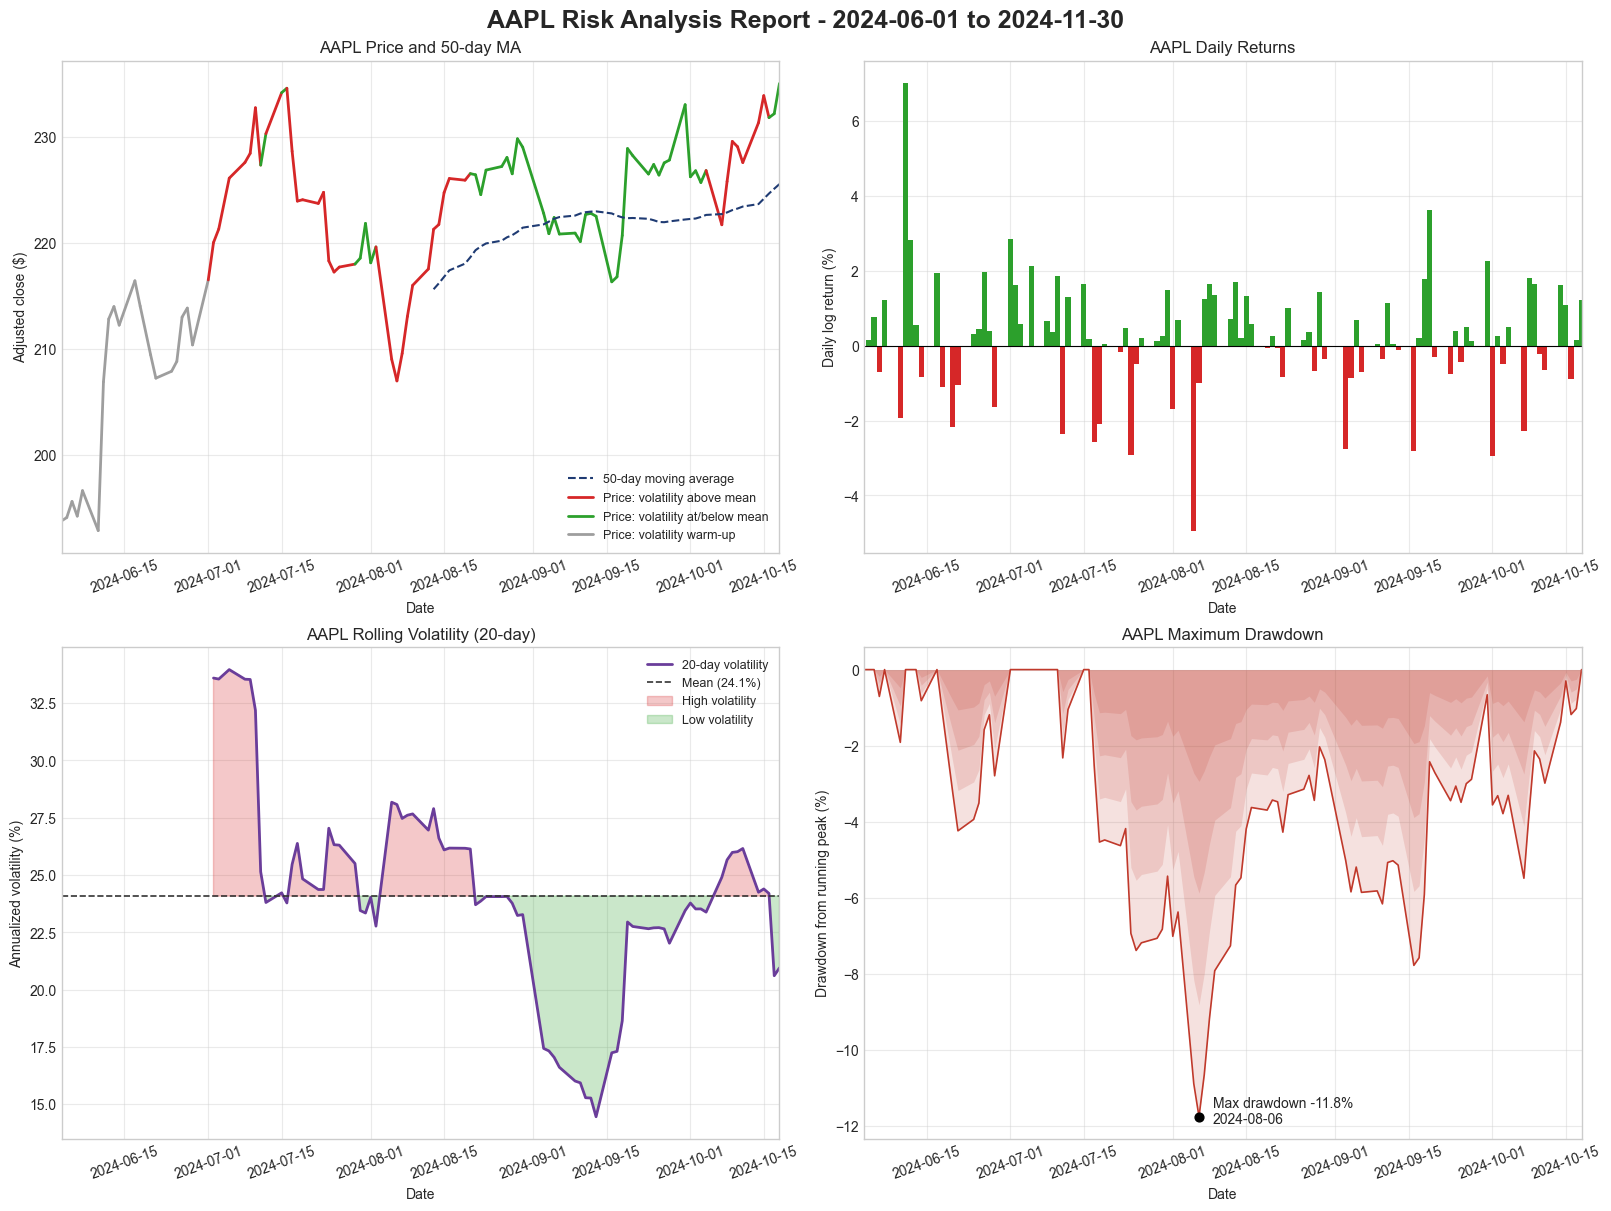

In [11]:
def plot_risk_report(df, ticker, start_date, end_date):
    """Draw the 2x2 risk report and return the Figure."""
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout='constrained')
    fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=18, fontweight='bold')
    mean_vol = df['volatility'].mean()

    ax = axes[0, 0]
    for i in range(1, len(df)):
        vol = df['volatility'].iloc[i]
        color = COLORS['warmup'] if pd.isna(vol) else (COLORS['high'] if vol > mean_vol else COLORS['low'])
        ax.plot(df.index[i - 1:i + 1], df['adj_close'].iloc[i - 1:i + 1], color=color, linewidth=2)
    ax.plot(df.index, df['ma_50'], color=COLORS['ma'], linewidth=1.5, linestyle='--', label='50-day moving average')
    ax.plot([], [], color=COLORS['high'], linewidth=2, label='Price: volatility above mean')
    ax.plot([], [], color=COLORS['low'], linewidth=2, label='Price: volatility at/below mean')
    ax.plot([], [], color=COLORS['warmup'], linewidth=2, label='Price: volatility warm-up')
    if df['ma_50'].notna().sum() == 0:
        ax.text(0.02, 0.04, f'50-day MA unavailable: only {len(df)} prices', transform=ax.transAxes, color=COLORS['ma'])
    ax.set(title=f'{ticker} Price and 50-day MA', xlabel='Date', ylabel='Adjusted close ($)')
    ax.legend(loc='best', fontsize=9)

    ax = axes[0, 1]
    ret_pct = df['log_return'] * 100
    ax.bar(df.index, ret_pct, width=1.0, color=np.where(ret_pct.ge(0), COLORS['low'], COLORS['high']))
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set(title=f'{ticker} Daily Returns', xlabel='Date', ylabel='Daily log return (%)')

    ax = axes[1, 0]
    vol_pct = df['volatility'] * 100
    ax.plot(df.index, vol_pct, color=COLORS['vol'], linewidth=2, label=f'{VOL_WINDOW}-day volatility')
    ax.axhline(mean_vol * 100, color=COLORS['mean'], linestyle='--', linewidth=1.2, label=f'Mean ({mean_vol:.1%})')
    ax.fill_between(df.index, vol_pct, mean_vol * 100, where=df['volatility'] > mean_vol,
                    color=COLORS['high'], alpha=0.25, interpolate=True, label='High volatility')
    ax.fill_between(df.index, vol_pct, mean_vol * 100, where=df['volatility'] <= mean_vol,
                    color=COLORS['low'], alpha=0.25, interpolate=True, label='Low volatility')
    ax.set(title=f'{ticker} Rolling Volatility ({VOL_WINDOW}-day)', xlabel='Date', ylabel='Annualized volatility (%)')
    ax.legend(loc='best', fontsize=9)

    ax = axes[1, 1]
    dd_pct = df['drawdown'] * 100
    for fraction in [1.0, 0.75, 0.5, 0.25]:
        ax.fill_between(df.index, dd_pct * fraction, 0, color=COLORS['drawdown'], alpha=0.15, linewidth=0)
    ax.plot(df.index, dd_pct, color=COLORS['drawdown'], linewidth=1.2)
    worst_date = df['drawdown'].idxmin()
    ax.scatter([worst_date], [dd_pct.loc[worst_date]], color='black', zorder=3, s=40)
    ax.annotate(f'Max drawdown {dd_pct.loc[worst_date]:.1f}%\n{worst_date.date()}', (worst_date, dd_pct.loc[worst_date]),
                xytext=(10, -5), textcoords='offset points', fontsize=10)
    ax.set(title=f'{ticker} Maximum Drawdown', xlabel='Date', ylabel='Drawdown from running peak (%)')

    for ax in axes.flat:
        ax.set_xlim(df.index.min(), df.index.max())
        ax.grid(True, alpha=0.4)
        ax.tick_params(axis='x', labelrotation=20)
    return fig

fig = plot_risk_report(df, ticker, start_date, end_date)
plt.show()

## Summary statistics

In [12]:
def summary_statistics(df):
    """Whole-period metrics as fractions (NaN where undefined)."""
    returns = df['log_return'].dropna()
    n = len(returns)
    ups, downs = returns[returns > 0], returns[returns < 0]
    return {
        'Total Return': df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1,
        'Annualized Return': np.exp(returns.sum() * TRADING_DAYS / n) - 1 if n > 0 else np.nan,
        'Annualized Volatility': returns.std() * np.sqrt(TRADING_DAYS),
        'Sharpe Ratio': calculate_sharpe_ratio(returns, RISK_FREE_RATE),
        'Maximum Drawdown': df['drawdown'].min(),
        'Best Day': returns.max(),
        'Worst Day': returns.min(),
        'Positive Days': len(ups) / n if n > 0 else np.nan,
        'Average Up Day': ups.mean() if len(ups) > 0 else np.nan,
        'Average Down Day': downs.mean() if len(downs) > 0 else np.nan,
    }


def format_metric(name, value):
    """Display format: Sharpe as a number, signed percentages for returns, plain percentages otherwise."""
    if pd.isna(value):
        return 'N/A'
    if name == 'Sharpe Ratio':
        return f'{value:.2f}'
    if name in ['Annualized Volatility', 'Positive Days']:
        return f'{value:.2%}'
    return f'{value:+.2%}'

metrics = summary_statistics(df)
assert np.isclose(np.expm1(df['log_return'].sum()), metrics['Total Return'])
summary_table = pd.DataFrame({'Metric': list(metrics), 'Value': [format_metric(k, v) for k, v in metrics.items()]})
print(f'{ticker}: {first_date} to {last_date} ({len(df)} prices, {df["log_return"].notna().sum()} returns)')
display(summary_table.set_index('Metric'))

AAPL: 2024-06-03 to 2024-10-18 (97 prices, 96 returns)


,Value
Metric,
Total Return,+21.25%
Annualized Return,+65.84%
Annualized Volatility,25.45%
Sharpe Ratio,1.91
Maximum Drawdown,-11.75%
Best Day,+7.01%
Worst Day,-4.94%
Positive Days,62.50%
Average Up Day,+1.09%


## Saving results for the batch run

In [13]:
sb.glue('summary', {
    'ticker': ticker, 'start_date': start_date, 'end_date': end_date,
    'first_date': str(first_date), 'last_date': str(last_date), 'trading_days': int(len(df)),
    'avg_daily_return': float(df['log_return'].mean()),
    'avg_volatility': float(df['volatility'].mean()),
    'max_drawdown': float(metrics['Maximum Drawdown']),
    'sharpe_ratio': float(metrics['Sharpe Ratio']),
    'total_return': float(metrics['Total Return']),
    'annualized_return': float(metrics['Annualized Return']),
    'annualized_volatility': float(metrics['Annualized Volatility']),
    'repaired_rows': int(df[['price_repaired', 'volume_repaired', 'adj_close_repaired']].any(axis=1).sum()),
})
print('Results saved with scrapbook.')

Results saved with scrapbook.
